# Actividad 3: Colab–VS Code Bridge

**Curso:** TI2006B · **Alumno:** A01234560

**Pregunta:** ¿Los estudiantes que estudian más horas a la semana sacan mejor calificación?

**Origen de los datos:** los datos son **sintéticos**. Se generan dentro de este notebook con `numpy` y una semilla fija (`SEED = 2006`). No se usan archivos locales, Google Drive ni datos personales.

**Resultado esperado:** una tabla con los primeros registros, la correlación entre horas de estudio y calificación, el promedio por rango de horas y una gráfica de dispersión con la recta de ajuste.

**Cómo correrlo:** abre el notebook desde GitHub en Colab (Archivo → Abrir notebook → GitHub) y usa *Entorno de ejecución → Desconectar y borrar entorno* y luego *Ejecutar todo*. No depende de variables de sesiones anteriores.

## 1. Setup
Imprime la versión de Python y de cada paquete, y dice en qué runtime se está ejecutando. Solo se usan `numpy`, `pandas` y `matplotlib`, que ya vienen instalados en Colab, así que no hace falta `pip install`. Si tu entorno no los tiene, descomenta la línea de instalación.

In [1]:
# %pip install numpy pandas matplotlib   # solo si tu entorno no los trae

import sys, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

EN_COLAB = "google.colab" in sys.modules
print("Python     :", sys.version.split()[0])
print("Sistema    :", platform.system(), platform.release())
print("Runtime    :", "Google Colab" if EN_COLAB else "Local (Jupyter / VS Code)")
print("numpy      :", np.__version__)
print("pandas     :", pd.__version__)
print("matplotlib :", matplotlib.__version__)

Python     : 3.13.18
Sistema    : Linux 6.6.159+
Runtime    : Google Colab
numpy      : 2.4.6
pandas     : 2.2.3
matplotlib : 3.10.0


## 2. Datos sintéticos
200 estudiantes ficticios. La calificación se construye como `55 + 2.2 × horas + ruido` y se recorta al rango 0–100, así que esperamos una relación positiva.

In [2]:
SEED = 2006
rng = np.random.default_rng(SEED)

n = 200
horas = rng.uniform(0, 15, n).round(1)
calificacion = np.clip(55 + 2.2 * horas + rng.normal(0, 8, n), 0, 100).round(1)

df = pd.DataFrame({"horas_estudio": horas, "calificacion": calificacion})
print(df.shape)
df.head()

(200, 2)


,horas_estudio,calificacion
0,13.1,77.7
1,8.4,72.7
2,4.5,58.0
3,5.4,69.5
4,4.4,59.6


## 3. Análisis

In [3]:
r = df["horas_estudio"].corr(df["calificacion"])
pendiente, intercepto = np.polyfit(df["horas_estudio"], df["calificacion"], 1)

df["rango_horas"] = pd.cut(df["horas_estudio"], bins=[0, 5, 10, 15],
                           labels=["0–5 h", "5–10 h", "10–15 h"], include_lowest=True)
resumen = (df.groupby("rango_horas", observed=True)["calificacion"]
             .agg(["count", "mean"]).round(1)
             .rename(columns={"count": "estudiantes", "mean": "calificacion_promedio"}))

print(f"Correlación (Pearson): {r:.2f}")
print(f"Recta de ajuste: calificación = {intercepto:.1f} + {pendiente:.2f} × horas")
resumen

Correlación (Pearson): 0.77
Recta de ajuste: calificación = 54.1 + 2.33 × horas


,estudiantes,calificacion_promedio
rango_horas,,
0–5 h,60,59.6
5–10 h,73,72.1
10–15 h,67,83.3


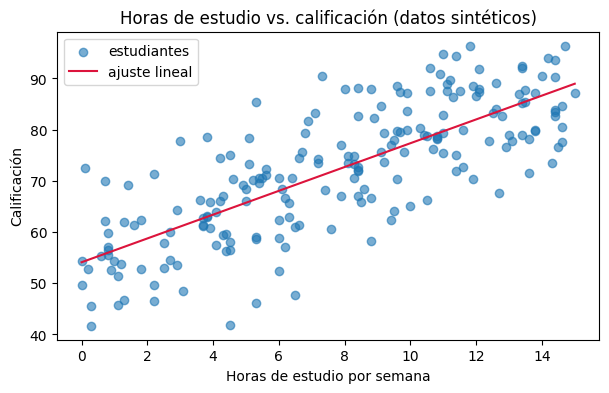

In [4]:
x = np.linspace(0, 15, 50)
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(df["horas_estudio"], df["calificacion"], alpha=0.6, label="estudiantes")
ax.plot(x, intercepto + pendiente * x, color="crimson", label="ajuste lineal")
ax.set_xlabel("Horas de estudio por semana")
ax.set_ylabel("Calificación")
ax.set_title("Horas de estudio vs. calificación (datos sintéticos)")
ax.legend()
plt.show()

## 4. Conclusión

In [5]:
print(f"Con estos datos sintéticos, la correlación es {r:.2f}: a más horas de estudio, mejor calificación.")
print(f"Cada hora extra se asocia con unos {pendiente:.1f} puntos más en promedio.")
print(f"El rango de 10–15 h promedia {resumen.loc['10–15 h', 'calificacion_promedio']} "
      f"contra {resumen.loc['0–5 h', 'calificacion_promedio']} del rango de 0–5 h.")

Con estos datos sintéticos, la correlación es 0.77: a más horas de estudio, mejor calificación.
Cada hora extra se asocia con unos 2.3 puntos más en promedio.
El rango de 10–15 h promedia 83.3 contra 59.6 del rango de 0–5 h.


Los datos son inventados y la relación se programó a propósito, así que el resultado **no** dice nada sobre estudiantes reales. El objetivo es demostrar que el notebook corre igual en Colab y en VS Code desde una sesión limpia.

**Notebook guardado vs. runtime:** este archivo `.ipynb` guarda el código, el texto y las salidas de la última ejecución. **No** guarda el runtime: ni las variables en memoria, ni los paquetes instalados, ni los archivos de la máquina donde corrió. Por eso la celda de setup registra versiones y los datos se generan aquí mismo con una semilla fija.